# OJO


In [5]:
import torch

# Verificar si CUDA está disponible
cuda_disponible = torch.cuda.is_available()
print(f"¿CUDA está disponible?: {cuda_disponible}")

if cuda_disponible:
    print(f"Dispositivo actual: {torch.cuda.get_device_name(0)}")
    print(f"Cantidad de GPUs: {torch.cuda.device_count()}")
else:
    print("Actualmente el entorno está configurado para usar solo CPU.")

¿CUDA está disponible?: True
Dispositivo actual: NVIDIA A100-SXM4-40GB
Cantidad de GPUs: 1


T1


In [ ]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict

# Entorno base
env = gym.make("FrozenLake-v1", is_slippery=True)
nS = env.observation_space.n  # 16 estados
nA = env.action_space.n  # 4 acciones

# Hiperparámetros comunes
ALPHA = 0.08  # tasa de aprendizaje
GAMMA = 0.99  # descuento
EPSILON = 0.25  # exploración inicial
EPS_DECAY = 0.996  # decaimiento por episodio
EPS_MIN = 0.01  # exploración mínima
N_EPISODES = 3000

# Q-table base (para comparación)
Q_base = np.zeros((nS, nA))


def epsilon_greedy(Q, state, eps=EPSILON):
    if np.random.random() < eps:
        return env.action_space.sample()
    max_val = np.max(Q[state])
    best_actions = np.where(Q[state] == max_val)[0]
    return np.random.choice(best_actions)


def run_qlearning(n_eps=N_EPISODES, seed=99):
    np.random.seed(seed)
    Q = np.zeros((nS, nA))
    rewards = []
    for ep in range(n_eps):
        s, _ = env.reset(seed=seed + ep)
        eps = max(EPS_MIN, EPSILON * (EPS_DECAY**ep))
        ep_r = 0
        for _ in range(200):
            a = epsilon_greedy(Q, s, eps)
            s2, r, done, trunc, _ = env.step(a)
            target = r if done else r + GAMMA * np.max(Q[s2])
            Q[s, a] += ALPHA * (target - Q[s, a])
            s = s2
            ep_r += r
            if done or trunc:
                break
        rewards.append(ep_r)
    return Q, rewards

T2


In [ ]:
class TabularModel:
    """Modelo tabular empírico: almacena las transiciones (r, s') observadas por (s, a)."""

    def __init__(self):
        self.table = defaultdict(list)  # {(s, a): [(r, s_next), ...]}
        self.visited = []  # lista de (s, a) visitados

    def update(self, s, a, r, s_next):
        if (s, a) not in self.table:
            self.visited.append((s, a))
        self.table[(s, a)].append((r, s_next))

    def sample(self):
        """Devuelve (s, a) aleatorio de los visitados."""
        idx = np.random.randint(len(self.visited))
        return self.visited[idx]

    def predict(self, s, a):
        """Muestrea (r, s_next) según la distribución empírica observada."""
        transitions = self.table[(s, a)]
        return transitions[np.random.randint(len(transitions))]

    def __len__(self):
        return len(self.visited)


# Prueba rápida
model = TabularModel()
model.update(0, 1, 0.0, 4)
model.update(4, 2, 1.0, 15)
s_sample, a_sample = model.sample()
r_pred, s_next_pred = model.predict(s_sample, a_sample)
print(f"Muestreado: ({s_sample},{a_sample}) → r={r_pred}, s'={s_next_pred}")

Muestreado: (4,2) → r=1.0, s'=15


In [ ]:
def run_dyna_q(k=5, n_eps=N_EPISODES, seed=99):
    """Dyna-Q con k pasos de planificación."""
    np.random.seed(seed)
    Q = np.zeros((nS, nA))
    model = TabularModel()
    rewards = []

    for ep in range(n_eps):
        s, _ = env.reset(seed=seed + ep)
        eps = max(EPS_MIN, EPSILON * (EPS_DECAY**ep))
        ep_r = 0

        for _ in range(200):
            # ── PASO 1: Interacción real ──────────────────────
            a = epsilon_greedy(Q, s, eps)
            s2, r, done, trunc, _ = env.step(a)

            # ── PASO 2: Update directo Q-Learning ────────────
            td = r + GAMMA * np.max(Q[s2]) - Q[s, a]
            Q[s, a] += ALPHA * td

            # ── PASO 3: Actualizar modelo ─────────────────────
            model.update(s, a, r, s2)
            s = s2
            ep_r += r

            # ── PASO 4: Planificación (k pasos) ──────────────
            if len(model) > 0:
                for _ in range(k):
                    ps, pa = model.sample()
                    pr, ps2 = model.predict(ps, pa)
                    td_plan = pr + GAMMA * np.max(Q[ps2]) - Q[ps, pa]
                    Q[ps, pa] += ALPHA * td_plan

            if done or trunc:
                break
        rewards.append(ep_r)
    return Q, rewards


# Ejecutar para k = 0, 5, 20
results = {k: run_dyna_q(k=k) for k in [0, 5, 20]}

T3


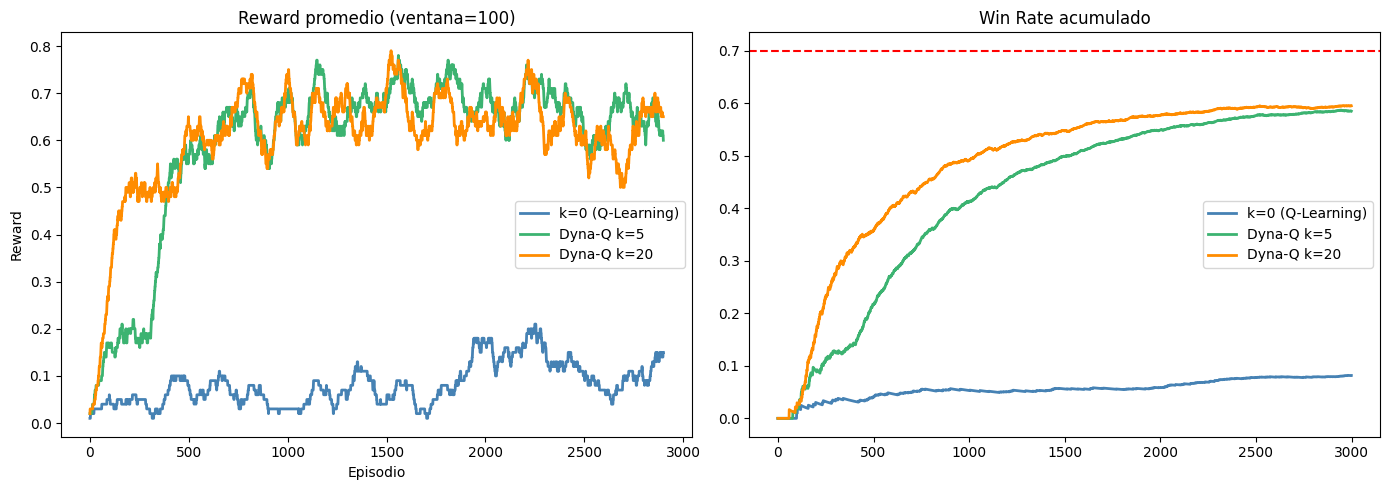

In [ ]:
def smooth(x, w=100):
    """Media móvil para suavizar curvas."""
    return np.convolve(x, np.ones(w) / w, mode="valid")


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = {0: "steelblue", 5: "mediumseagreen", 20: "darkorange"}
labels = {0: "k=0 (Q-Learning)", 5: "Dyna-Q k=5", 20: "Dyna-Q k=20"}

# Plot 1: Reward promedio suavizado
for k, (Q, rews) in results.items():
    axes[0].plot(smooth(rews), color=colors[k], label=labels[k], lw=2)
axes[0].set_title("Reward promedio (ventana=100)")
axes[0].legend()
axes[0].set_xlabel("Episodio")
axes[0].set_ylabel("Reward")

# Plot 2: Win rate acumulado
for k, (Q, rews) in results.items():
    win_rate = np.cumsum(rews) / (np.arange(len(rews)) + 1)
    axes[1].plot(win_rate, color=colors[k], label=labels[k], lw=2)
axes[1].set_title("Win Rate acumulado")
axes[1].legend()
axes[1].axhline(0.7, color="red", ls="--", label="Meta 70%")

plt.tight_layout()
plt.savefig("dyna_comparison.png", dpi=120)
plt.show()

T4


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

# Usamos CartPole para el World Model (estado continuo)
env_c = gym.make("CartPole-v1")
state_dim = env_c.observation_space.shape[0]  # 4
n_actions = env_c.action_space.n  # 2


def collect_dataset(n_episodes=200, policy="random"):
    """Recolecta transiciones (s, a, r, s') del entorno."""
    states, actions, rewards, next_states = [], [], [], []
    for ep in range(n_episodes):
        s, _ = env_c.reset(seed=ep)
        for _ in range(500):
            if policy == "random":
                a = env_c.action_space.sample()
            else:
                a = policy(s)
            s2, r, done, trunc, _ = env_c.step(a)
            states.append(s)
            actions.append(a)
            rewards.append(r)
            next_states.append(s2)
            s = s2
            if done or trunc:
                break

    return (
        torch.FloatTensor(np.array(states)),
        torch.LongTensor(np.array(actions)),
        torch.FloatTensor(np.array(rewards)).unsqueeze(1),
        torch.FloatTensor(np.array(next_states)),
    )


S, A, R, S2 = collect_dataset(n_episodes=1000)
print(f"Dataset: {S.shape[0]} transiciones recolectadas")
# Output esperado: Dataset: ~15000-30000 transiciones

Dataset: 21825 transiciones recolectadas


In [ ]:
class WorldModel(nn.Module):
    """Predice (s', r) dado (s, a) como one-hot."""

    def __init__(self, state_dim, n_actions):
        super().__init__()
        in_dim = state_dim + n_actions
        self.transition = nn.Sequential(
            nn.Linear(in_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 256),
            nn.ReLU(),
            nn.Linear(256, state_dim),  # → s'
        )
        self.reward_head = nn.Sequential(
            nn.Linear(in_dim, 128), nn.ReLU(), nn.Linear(128, 1)  # → r
        )

    def forward(self, s, a_onehot):
        x = torch.cat([s, a_onehot], dim=-1)
        return self.transition(x), self.reward_head(x)


# One-hot encoding de acciones
def to_onehot(a, n=2):
    oh = torch.zeros(len(a), n)
    oh.scatter_(1, a.unsqueeze(1), 1.0)
    return oh


# División Train (80%) / Test (20%)
split = int(0.8 * len(S))
S_train, A_train = S[:split], A[:split]
R_train, S2_train = R[:split], S2[:split]
A_oh_train = to_onehot(A_train)

# Entrenamiento
torch.manual_seed(42)
world_model = WorldModel(state_dim, n_actions)
optimizer = optim.Adam(world_model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

for epoch in range(50):
    s_pred, r_pred = world_model(S_train, A_oh_train)
    loss = loss_fn(s_pred, S2_train) + 0.5 * loss_fn(r_pred, R_train)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if epoch % 10 == 0:
        print(f"Epoch {epoch:3d}  Loss={loss.item():.4f}")

Epoch   0  Loss=0.6165
Epoch  10  Loss=0.1496
Epoch  20  Loss=0.0458
Epoch  30  Loss=0.0224
Epoch  40  Loss=0.0182


In [ ]:
# Evaluar el modelo en datos de test (hold-out 20%)
S_test, A_test = S[split:], A[split:]
R_test, S2_test = R[split:], S2[split:]
A_oh_test = to_onehot(A_test)

world_model.eval()
with torch.no_grad():
    s_pred_test, r_pred_test = world_model(S_test, A_oh_test)
    loss_s = loss_fn(s_pred_test, S2_test).item()
    loss_r = loss_fn(r_pred_test, R_test).item()

print(f"Loss transición (test): {loss_s:.4f}")
print(f"Loss recompensa (test): {loss_r:.4f}")

# Comparar 5 predicciones vs realidad
for i in range(5):
    print(f"Real s': {S2_test[i].numpy().round(3)}")
    print(f"Pred s': {s_pred_test[i].numpy().round(3)}")
    print("---")

Loss transición (test): 0.0010
Loss recompensa (test): 0.0203
Real s': [-0.002 -0.227 -0.002  0.289]
Pred s': [-0.001 -0.218  0.     0.268]
---
Real s': [-0.007 -0.422  0.004  0.581]
Pred s': [-0.018 -0.428  0.011  0.57 ]
---
Real s': [-0.015 -0.227  0.016  0.29 ]
Pred s': [-0.017 -0.222  0.023  0.311]
---
Real s': [-0.02  -0.423  0.022  0.587]
Pred s': [-0.025 -0.425  0.017  0.573]
---
Real s': [-0.028 -0.618  0.033  0.887]
Pred s': [-0.033 -0.617  0.018  0.866]
---


In [ ]:
def model_rollout(wm, start_state, policy_fn, H=5):
    """Genera H pasos sintéticos desde start_state."""
    traj = []
    s = torch.FloatTensor(start_state).unsqueeze(0)
    for _ in range(H):
        a = policy_fn(s.numpy()[0])
        a_oh = to_onehot(torch.LongTensor([a]))
        with torch.no_grad():
            s_next, r = wm(s, a_oh)
        traj.append((s.numpy()[0], a, r.item(), s_next.numpy()[0]))
        s = s_next
    return traj


# Generar rollout desde estado inicial
s0, _ = env_c.reset(seed=0)
rand_policy = lambda s: env_c.action_space.sample()
traj = model_rollout(world_model, s0, rand_policy, H=10)

for i, (s, a, r, s2) in enumerate(traj):
    print(f"  t={i}: a={a}, r={r:.2f}, |s'|={np.linalg.norm(s2):.3f}")

  t=0: a=1, r=0.96, |s'|=0.368
  t=1: a=0, r=0.88, |s'|=0.092
  t=2: a=0, r=0.86, |s'|=0.268
  t=3: a=1, r=0.99, |s'|=0.113
  t=4: a=0, r=0.86, |s'|=0.239
  t=5: a=1, r=0.99, |s'|=0.141
  t=6: a=0, r=0.86, |s'|=0.212
  t=7: a=1, r=0.98, |s'|=0.173
  t=8: a=0, r=0.86, |s'|=0.186
  t=9: a=0, r=0.86, |s'|=0.509


### Visualización del World Model

La primera figura compara cada componente del estado real con la predicción a un paso sobre el conjunto de prueba: cuanto más cerca esté un punto de la diagonal, menor es su error.

La segunda figura muestra el error durante un rollout: el entorno y el modelo parten del mismo estado y reciben las mismas acciones. El rollout se detiene si termina el episodio. El error es la distancia euclidiana entre estados sin normalizar, por lo que combina componentes con distintas unidades y escalas; una sola trayectoria es ilustrativa y no resume el rendimiento general.


In [ ]:
# 1. Comparar predicciones a un paso con los estados reales de test.
nombres = [
    "Posición del carrito",
    "Velocidad del carrito",
    "Ángulo del poste",
    "Velocidad angular del poste",
]
reales = S2_test.numpy()
predichos = s_pred_test.numpy()

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for i, ax in enumerate(axes.flat):
    ax.scatter(reales[:, i], predichos[:, i], s=5, alpha=0.25)
    limite_min = min(reales[:, i].min(), predichos[:, i].min())
    limite_max = max(reales[:, i].max(), predichos[:, i].max())
    ax.plot(
        [limite_min, limite_max],
        [limite_min, limite_max],
        "r--",
        label="Predicción perfecta",
    )
    ax.set_title(nombres[i])
    ax.set_xlabel("Estado real")
    ax.set_ylabel("Estado predicho")
    ax.legend()

fig.suptitle("World Model: predicciones a un paso en test")
plt.tight_layout()
plt.show()

# 2. Comparar un rollout del modelo con el entorno usando las mismas acciones.
horizonte = 50
rng = np.random.default_rng(42)
env_eval = gym.make("CartPole-v1")
estado_real, _ = env_eval.reset(seed=42)
estado_modelo = torch.as_tensor(estado_real, dtype=torch.float32).unsqueeze(0)
errores_rollout = []

world_model.eval()
with torch.no_grad():
    for paso in range(horizonte):
        accion = int(rng.integers(n_actions))
        estado_real, _, terminado, truncado, _ = env_eval.step(accion)
        accion_onehot = to_onehot(torch.tensor([accion]))
        estado_modelo, _ = world_model(estado_modelo, accion_onehot)
        error = np.linalg.norm(estado_real - estado_modelo.squeeze(0).numpy())
        errores_rollout.append(error)
        if terminado or truncado:
            break

env_eval.close()
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(errores_rollout) + 1), errores_rollout, marker="o")
plt.title("Error del World Model durante un rollout")
plt.xlabel("Paso del rollout")
plt.ylabel("Distancia euclidiana entre estados")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

T5:


### T5: Preguntas de análisis

**1. En Dyna-Q, ¿qué sucede si el entorno CAMBIA después de haber aprendido el modelo (entorno no-estacionario)? ¿Cómo lo resolverías?**

Si cambian las transiciones o las recompensas, el modelo aprendido puede quedar desactualizado. La planificación reutilizaría experiencias antiguas y actualizaría la tabla Q hacia una dinámica que ya no existe; con muchos pasos de planificación, este efecto puede reforzarse. En este notebook, `TabularModel` guarda todas las transiciones y las muestrea por igual, por lo que se adaptaría lentamente.

Para adaptarlo, conservaría una ventana de experiencias recientes o daría más peso a las observaciones nuevas, y mantendría exploración suficiente para detectar cambios. También reduciría temporalmente `k` cuando se detecte un cambio y lo aumentaría cuando el modelo vuelva a ser confiable.

**2. Tu World Model tiene loss de transición = 0.001 en training pero = 0.5 en test. ¿Qué problema tiene? ¿Cómo se relaciona con el compounding error?**

Una pérdida de transición de 0.001 en entrenamiento y 0.5 en prueba indica una brecha grande de generalización: el modelo predice bien los datos de entrenamiento, pero falla en datos no vistos. Puede deberse a sobreajuste o a una diferencia entre las distribuciones de ambos conjuntos; conviene revisar la división, la cobertura de estados y las escalas antes de concluir la causa.

En un rollout, cada estado predicho se usa como entrada del siguiente paso. Un error inicial puede llevar el modelo a estados poco conocidos y producir nuevos errores que se acumulen o amplifiquen (_compounding error_). Por ello, evaluaría también el error a varios horizontes y usaría rollouts cortos cuando las predicciones largas no sean confiables. Esta pregunta plantea valores hipotéticos: en la salida guardada de T4, la pérdida de transición en prueba es 0.0010.

**3. Compara el k óptimo que encontraste en T3 con el error de tu modelo de T4. ¿Existe relación? Argumenta por qué k óptimo ∝ 1/ε_model.**

En T3 se comparan `k = 0, 5, 20` para Dyna-Q en FrozenLake; el mejor valor debe identificarse a partir de las curvas y de un criterio explícito, como la velocidad de convergencia o la recompensa. La pérdida de transición de T4 es 0.0010 en prueba, pero corresponde a un World Model distinto, entrenado para CartPole. Por tanto, no se puede usar esa pérdida para demostrar una relación con el `k` óptimo de T3.

La idea `k óptimo ∝ 1 / ε_model` es una **heurística**, no una ley demostrada aquí: si el modelo es más preciso, más actualizaciones simuladas pueden aprovecharlo; si es menos preciso, muchas actualizaciones pueden propagar y reforzar sus errores. El valor óptimo también depende de la cobertura del modelo, el entorno, el costo de cómputo y la métrica elegida. Para comprobar la relación habría que variar el error y `k` en el mismo entorno, repetir con varias semillas y comparar el rendimiento. Además, `k` cuenta actualizaciones de planificación; no es lo mismo que el horizonte `H` de un rollout.

**4. ¿Para qué tipo de entorno preferirías un World Model estocástico (Gaussian MLP) sobre uno determinístico? Da un ejemplo concreto.**

Lo preferiría cuando un mismo estado y acción pueden producir distintos estados siguientes por ruido real del entorno. Por ejemplo, un robot móvil puede terminar en posiciones distintas al ejecutar el mismo movimiento debido a variaciones en la fricción. Una Gaussian MLP puede predecir una media y una varianza para representar esa incertidumbre y generar posibles transiciones, mientras que una predicción determinística entrega un único resultado. Una sola gaussiana puede ser insuficiente si los resultados posibles forman varios grupos separados.
